In [1]:
!pip install -q "gymnasium[box2d]"
!pip install -q swig
!pip install -q torch torchvision
!pip install -q matplotlib pandas numpy imageio

In [2]:
import gymnasium as gym

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random
import math
import os
import time
from collections import deque

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

print("PyTorch version:", torch.__version__)
print("Gymnasium version:", gym.__version__)

PyTorch version: 2.11.0+cu128
Gymnasium version: 1.3.0


### Deep Q-Network (DQN) Definition

Here, we define the `DQN` class as a simple feed-forward neural network using PyTorch's `nn.Module`. This network will take the environment's state as input and output Q-values for each possible action.

In [3]:
import gymnasium as gym

env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

print(env)

<TimeLimit<OrderEnforcing<PassiveEnvChecker<LunarLander<LunarLander-v3>>>>>


In [4]:
class DQN(nn.Module):
    def __init__(self, state_size, action_size):
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(state_size, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, action_size)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

# Get state and action sizes from the environment
# The LunarLander state space is 8 continuous values.
state_size = env.observation_space.shape[0]
# The LunarLander action space is 4 discrete actions.
action_size = env.action_space.n

# Instantiate the DQN model
dqn_model = DQN(state_size, action_size)

# Define optimizer and loss function (typical for DQN training)
optimizer = optim.Adam(dqn_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

print(f"DQN model created with input size {state_size} and output size {action_size}.")
print(dqn_model)

DQN model created with input size 8 and output size 4.
DQN(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=4, bias=True)
)


### Epsilon-Greedy Action Selection

This function implements the epsilon-greedy strategy to balance exploration and exploitation during training. With probability `epsilon`, a random action is chosen (exploration); otherwise, the action with the highest predicted Q-value from the `dqn_model` is selected (exploitation).

In [5]:
def select_action_with_dqn(state, model, epsilon):
    if random.random() < epsilon:
        return env.action_space.sample() # Explore: choose a random action
    else:
        # Exploit: choose the action with the highest Q-value from the model
        state_tensor = torch.from_numpy(state).float().unsqueeze(0)
        with torch.no_grad():
            q_values = model(state_tensor)
        return torch.argmax(q_values).item()

print("Action selection function redefined.")

Action selection function redefined.


In [6]:
def select_action_with_dqn(state, model, epsilon):
    if random.random() < epsilon:
        return env.action_space.sample() # Explore: choose a random action
    else:
        # Exploit: choose the action with the highest Q-value from the model
        state_tensor = torch.from_numpy(state).float().unsqueeze(0)
        with torch.no_grad():
            q_values = model(state_tensor)
        return torch.argmax(q_values).item()

print("Action selection function defined.")

Action selection function defined.


Now, we will modify the cell with the error to use the `select_action_with_dqn` function.

In [7]:
env = gym.make(
    "FrozenLake-v1",
    is_slippery=False
)

print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)

Number of states: 16
Number of actions: 4


In [8]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q_table = np.zeros((n_states, n_actions))

print("Q-table shape:", Q_table.shape)
print(Q_table)

Q-table shape: (16, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [9]:
learning_rate = 0.8
discount_factor = 0.95

epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995

num_episodes = 1000

In [10]:
episode_rewards = []

for episode in range(num_episodes):

    state, info = env.reset()
    total_reward = 0

    while True:

        # ε-greedy action selection
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(Q_table[state])

        # Take action
        next_state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated

        # Bellman Q-learning update
        best_next_action = np.max(Q_table[next_state])

        Q_table[state, action] = Q_table[state, action] + learning_rate * (
            reward
            + discount_factor * best_next_action
            - Q_table[state, action]
        )

        state = next_state
        total_reward += reward

        if done:
            break

    # Decay exploration
    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )

    episode_rewards.append(total_reward)

env.close()

print("Training completed.")

Training completed.


In [11]:
print("Learned Q-table:")
print(np.round(Q_table, 3))

Learned Q-table:
[[0.735 0.774 0.698 0.735]
 [0.735 0.    0.    0.559]
 [0.559 0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.774 0.815 0.    0.735]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.815 0.    0.857 0.774]
 [0.815 0.902 0.815 0.   ]
 [0.857 0.76  0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.    0.902 0.95  0.857]
 [0.902 0.95  1.    0.815]
 [0.    0.    0.    0.   ]]


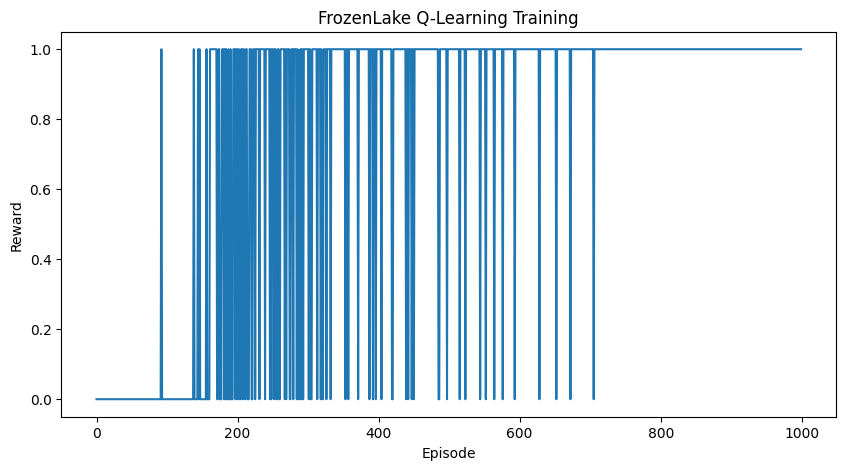

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(episode_rewards)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("FrozenLake Q-Learning Training")

plt.show()

In [13]:
!pip install -q "gymnasium[box2d]"
!pip install -q swig

In [14]:
import gymnasium as gym

env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

print(env)

<TimeLimit<OrderEnforcing<PassiveEnvChecker<LunarLander<LunarLander-v3>>>>>


In [15]:
import pandas as pd
import numpy as np

NUM_EPISODES = 100

all_data = []

for episode in range(1, NUM_EPISODES + 1):

    state, info = env.reset()

    step = 0
    episode_reward = 0

    while True:

        # Choose an action
        action = env.action_space.sample()

        # REAL interaction with LunarLander-v3
        next_state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated

        all_data.append({
            "episode": episode,
            "step": step,

            "x_position": state[0],
            "y_position": state[1],
            "x_velocity": state[2],
            "y_velocity": state[3],
            "angle": state[4],
            "angular_velocity": state[5],
            "left_leg_contact": state[6],
            "right_leg_contact": state[7],

            "action": action,
            "reward": reward,

            "next_x_position": next_state[0],
            "next_y_position": next_state[1],
            "next_x_velocity": next_state[2],
            "next_y_velocity": next_state[3],
            "next_angle": next_state[4],
            "next_angular_velocity": next_state[5],
            "next_left_leg_contact": next_state[6],
            "next_right_leg_contact": next_state[7],

            "done": done
        })

        state = next_state
        episode_reward += reward
        step += 1

        if done:
            break

env.close()

# Create the complete interaction dataset
df = pd.DataFrame(all_data)

print("Dataset shape:", df.shape)

Dataset shape: (9343, 21)


In [16]:
df.head(21)

,episode,step,x_position,y_position,x_velocity,y_velocity,angle,angular_velocity,left_leg_contact,right_leg_contact,...,reward,next_x_position,next_y_position,next_x_velocity,next_y_velocity,next_angle,next_angular_velocity,next_left_leg_contact,next_right_leg_contact,done
0,1,0,0.004273,1.417698,0.432795,0.301216,-0.004945,-0.098035,0.0,0.0,...,-3.152613,0.008434,1.425388,0.421570,0.341776,-0.010351,-0.108142,0.0,0.0,False
1,1,1,0.008434,1.425388,0.421570,0.341776,-0.010351,-0.108142,0.0,0.0,...,-0.721197,0.012683,1.432468,0.432612,0.314574,-0.017968,-0.152342,0.0,0.0,False
2,1,2,0.012683,1.432468,0.432612,0.314574,-0.017968,-0.152342,0.0,0.0,...,-4.344985,0.016983,1.440334,0.437516,0.349511,-0.025419,-0.149051,0.0,0.0,False
3,1,3,0.016983,1.440334,0.437516,0.349511,-0.025419,-0.149051,0.0,0.0,...,0.146316,0.021283,1.447601,0.437537,0.322827,-0.032871,-0.149038,0.0,0.0,False
4,1,4,0.021283,1.447601,0.437537,0.322827,-0.032871,-0.149038,0.0,0.0,...,-5.345620,0.025706,1.455816,0.449380,0.364923,-0.039897,-0.140538,0.0,0.0,False
5,1,5,0.025706,1.455816,0.449380,0.364923,-0.039897,-0.140538,0.0,0.0,...,0.908983,0.030067,1.463428,0.441713,0.338198,-0.045383,-0.109732,0.0,0.0,False
6,1,6,0.030067,1.463428,0.441713,0.338198,-0.045383,-0.109732,0.0,0.0,...,-0.642470,0.034504,1.470433,0.451133,0.311036,-0.052761,-0.147572,0.0,0.0,False
7,1,7,0.034504,1.470433,0.451133,0.311036,-0.052761,-0.147572,0.0,0.0,...,1.030871,0.038866,1.476838,0.441685,0.284470,-0.058239,-0.109563,0.0,0.0,False
8,1,8,0.038866,1.476838,0.441685,0.284470,-0.058239,-0.109563,0.0,0.0,...,1.098017,0.043162,1.482640,0.433505,0.257720,-0.062078,-0.076802,0.0,0.0,False
9,1,9,0.043162,1.482640,0.433505,0.257720,-0.062078,-0.076802,0.0,0.0,...,1.601610,0.047366,1.487844,0.421944,0.231256,-0.063598,-0.030390,0.0,0.0,False


In [17]:
print(df.columns.tolist())

['episode', 'step', 'x_position', 'y_position', 'x_velocity', 'y_velocity', 'angle', 'angular_velocity', 'left_leg_contact', 'right_leg_contact', 'action', 'reward', 'next_x_position', 'next_y_position', 'next_x_velocity', 'next_y_velocity', 'next_angle', 'next_angular_velocity', 'next_left_leg_contact', 'next_right_leg_contact', 'done']


In [18]:
print("Total transitions:", len(df))
print("Total episodes:", df["episode"].nunique())
print("Total columns:", len(df.columns))

Total transitions: 9343
Total episodes: 100
Total columns: 21


In [19]:
df.to_csv(
    "LunarLander_v3_real_interaction_data.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [20]:
env.step(action)

(array([ 0.40946645,  0.03771902, -0.19157776, -0.42454776, -0.04670072,
        -5.241458  ,  0.        ,  0.        ], dtype=float32),
 -100,
 True,
 False,
 {})

In [21]:
action = select_action_with_dqn(state, dqn_model, epsilon)

In [22]:
print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (9343, 21)


,episode,step,x_position,y_position,x_velocity,y_velocity,angle,angular_velocity,left_leg_contact,right_leg_contact,...,reward,next_x_position,next_y_position,next_x_velocity,next_y_velocity,next_angle,next_angular_velocity,next_left_leg_contact,next_right_leg_contact,done
0,1,0,0.004273,1.417698,0.432795,0.301216,-0.004945,-0.098035,0.0,0.0,...,-3.152613,0.008434,1.425388,0.421570,0.341776,-0.010351,-0.108142,0.0,0.0,False
1,1,1,0.008434,1.425388,0.421570,0.341776,-0.010351,-0.108142,0.0,0.0,...,-0.721197,0.012683,1.432468,0.432612,0.314574,-0.017968,-0.152342,0.0,0.0,False
2,1,2,0.012683,1.432468,0.432612,0.314574,-0.017968,-0.152342,0.0,0.0,...,-4.344985,0.016983,1.440334,0.437516,0.349511,-0.025419,-0.149051,0.0,0.0,False
3,1,3,0.016983,1.440334,0.437516,0.349511,-0.025419,-0.149051,0.0,0.0,...,0.146316,0.021283,1.447601,0.437537,0.322827,-0.032871,-0.149038,0.0,0.0,False
4,1,4,0.021283,1.447601,0.437537,0.322827,-0.032871,-0.149038,0.0,0.0,...,-5.345620,0.025706,1.455816,0.449380,0.364923,-0.039897,-0.140538,0.0,0.0,False
5,1,5,0.025706,1.455816,0.449380,0.364923,-0.039897,-0.140538,0.0,0.0,...,0.908983,0.030067,1.463428,0.441713,0.338198,-0.045383,-0.109732,0.0,0.0,False
6,1,6,0.030067,1.463428,0.441713,0.338198,-0.045383,-0.109732,0.0,0.0,...,-0.642470,0.034504,1.470433,0.451133,0.311036,-0.052761,-0.147572,0.0,0.0,False
7,1,7,0.034504,1.470433,0.451133,0.311036,-0.052761,-0.147572,0.0,0.0,...,1.030871,0.038866,1.476838,0.441685,0.284470,-0.058239,-0.109563,0.0,0.0,False
8,1,8,0.038866,1.476838,0.441685,0.284470,-0.058239,-0.109563,0.0,0.0,...,1.098017,0.043162,1.482640,0.433505,0.257720,-0.062078,-0.076802,0.0,0.0,False
9,1,9,0.043162,1.482640,0.433505,0.257720,-0.062078,-0.076802,0.0,0.0,...,1.601610,0.047366,1.487844,0.421944,0.231256,-0.063598,-0.030390,0.0,0.0,False


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9343 entries, 0 to 9342
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   episode                 9343 non-null   int64  
 1   step                    9343 non-null   int64  
 2   x_position              9343 non-null   float32
 3   y_position              9343 non-null   float32
 4   x_velocity              9343 non-null   float32
 5   y_velocity              9343 non-null   float32
 6   angle                   9343 non-null   float32
 7   angular_velocity        9343 non-null   float32
 8   left_leg_contact        9343 non-null   float32
 9   right_leg_contact       9343 non-null   float32
 10  action                  9343 non-null   int64  
 11  reward                  9343 non-null   float64
 12  next_x_position         9343 non-null   float32
 13  next_y_position         9343 non-null   float32
 14  next_x_velocity         9343 non-null   

In [24]:
df.describe()

,episode,step,x_position,y_position,x_velocity,y_velocity,angle,angular_velocity,left_leg_contact,right_leg_contact,action,reward,next_x_position,next_y_position,next_x_velocity,next_y_velocity,next_angle,next_angular_velocity,next_left_leg_contact,next_right_leg_contact
count,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000,9343.000000
mean,50.262228,48.562453,0.018229,0.981570,0.038529,-0.667652,-0.020111,-0.021110,0.014984,0.011024,1.491812,-1.862944,0.018616,0.966422,0.038395,-0.672019,-0.021274,-0.024193,0.020550,0.016911
std,28.686920,30.877589,0.280166,0.456289,0.569827,0.477198,0.447269,0.426004,0.121493,0.104424,1.119642,10.930116,0.285234,0.465348,0.573719,0.473489,0.462284,0.562675,0.141882,0.128942
min,1.000000,0.000000,-0.992599,-0.325191,-1.595162,-1.920319,-4.671909,-6.081613,0.000000,0.000000,0.000000,-100.000000,-1.005332,-0.334736,-1.690083,-1.920319,-4.953729,-6.081613,0.000000,0.000000
25%,25.000000,23.000000,-0.116051,0.638950,-0.454146,-1.054245,-0.186186,-0.136069,0.000000,0.000000,0.000000,-2.111538,-0.121184,0.615770,-0.455739,-1.054797,-0.191460,-0.138355,0.000000,0.000000
50%,50.000000,46.000000,0.013009,1.106859,0.085966,-0.684661,0.000261,-0.005262,0.000000,0.000000,1.000000,-1.127054,0.014372,1.090992,0.085966,-0.687480,0.000519,-0.005262,0.000000,0.000000
75%,75.000000,71.000000,0.162128,1.376695,0.468788,-0.312046,0.174707,0.120027,0.000000,0.000000,2.000000,0.049401,0.166240,1.369337,0.470902,-0.316252,0.179889,0.121660,0.000000,0.000000
max,100.000000,153.000000,0.991230,1.637990,1.624107,0.525318,2.772072,5.832623,1.000000,1.000000,3.000000,84.905453,1.006075,1.637990,2.050527,0.525318,2.930417,6.644010,1.000000,1.000000


In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DQN(nn.Module):

    def __init__(self, state_size=8, action_size=4):

        super(DQN, self).__init__()

        self.fc1 = nn.Linear(state_size, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, action_size)

    def forward(self, state):

        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [26]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

policy_net = DQN().to(device)

test_state = torch.FloatTensor(
    state
).unsqueeze(0).to(device)

q_values = policy_net(test_state)

print("Q-values:", q_values)
print("Q-value shape:", q_values.shape)

Using device: cuda
Q-values: tensor([[ 0.2009, -0.1432, -0.0705, -0.0824]], device='cuda:0',
       grad_fn=<AddmmBackward0>)
Q-value shape: torch.Size([1, 4])


In [27]:
from collections import deque
import random

class ReplayBuffer:

    def __init__(self, capacity=100000):

        self.buffer = deque(maxlen=capacity)

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        done
    ):

        self.buffer.append(
            (
                state,
                action,
                reward,
                next_state,
                done
            )
        )

    def sample(self, batch_size):

        batch = random.sample(
            self.buffer,
            batch_size
        )

        states, actions, rewards, next_states, dones = zip(*batch)

        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int64),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32)
        )

    def __len__(self):

        return len(self.buffer)

In [28]:
replay_buffer = ReplayBuffer(capacity=100000)

print("Replay buffer size:", len(replay_buffer))

Replay buffer size: 0


In [29]:
env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

state, info = env.reset()

for _ in range(100):

    action = env.action_space.sample()

    next_state, reward, terminated, truncated, info = env.step(action)

    done = terminated or truncated

    replay_buffer.add(
        state,
        action,
        reward,
        next_state,
        done
    )

    state = next_state

    if done:
        state, info = env.reset()

print("Replay buffer size:", len(replay_buffer))

env.close()

Replay buffer size: 100


In [30]:
target_net = DQN().to(device)

target_net.load_state_dict(
    policy_net.state_dict()
)

target_net.eval()

DQN(
  (fc1): Linear(in_features=8, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=4, bias=True)
)

In [31]:
optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

In [32]:
BATCH_SIZE = 64

GAMMA = 0.99

EPSILON_START = 1.0
EPSILON_END = 0.01
EPSILON_DECAY = 0.995

TARGET_UPDATE_FREQUENCY = 10

NUM_EPISODES = 1000

LEARNING_RATE = 1e-3

In [33]:
def train_step(
    policy_net,
    target_net,
    replay_buffer,
    optimizer
):

    if len(replay_buffer) < BATCH_SIZE:
        return None

    states, actions, rewards, next_states, dones = \
        replay_buffer.sample(BATCH_SIZE)

    states = torch.FloatTensor(states).to(device)
    actions = torch.LongTensor(actions).unsqueeze(1).to(device)
    rewards = torch.FloatTensor(rewards).unsqueeze(1).to(device)
    next_states = torch.FloatTensor(next_states).to(device)
    dones = torch.FloatTensor(dones).unsqueeze(1).to(device)

    # Current Q values
    current_q = policy_net(states).gather(
        1,
        actions
    )

    # Target Q values
    with torch.no_grad():

        next_q = target_net(
            next_states
        ).max(
            dim=1,
            keepdim=True
        )[0]

        target_q = rewards + (
            GAMMA * next_q * (1 - dones)
        )

    # Huber loss
    loss = F.smooth_l1_loss(
        current_q,
        target_q
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    return loss.item()

In [34]:
def select_action_with_dqn(state, model, epsilon):
    if random.random() < epsilon:
        return env.action_space.sample() # Explore: choose a random action
    else:
        # Exploit: choose the action with the highest Q-value from the model
        state_tensor = torch.from_numpy(state).float().unsqueeze(0).to(device) # <--- FIXED LINE
        with torch.no_grad():
            q_values = model(state_tensor)
        return torch.argmax(q_values).item()

env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

policy_net = DQN(state_size, action_size).to(device)
target_net = DQN(state_size, action_size).to(device)

target_net.load_state_dict(
    policy_net.state_dict()
)

optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=LEARNING_RATE
)

replay_buffer = ReplayBuffer(
    capacity=100000
)

episode_rewards = []
episode_losses = []

epsilon = EPSILON_START

for episode in range(1, NUM_EPISODES + 1):

    state, info = env.reset()

    total_reward = 0
    losses = []

    while True:

        # Choose action
        action = select_action_with_dqn(
            state,
            policy_net,
            epsilon
        )

        # Interact with LunarLander
        next_state, reward, terminated, truncated, info = \
            env.step(action)

        done = terminated or truncated

        # Store REAL experience
        replay_buffer.add(
            state,
            action,
            reward,
            next_state,
            done
        )

        # Train DQN
        loss = train_step(
            policy_net,
            target_net,
            replay_buffer,
            optimizer
        )

        if loss is not None:
            losses.append(loss)

        state = next_state

        total_reward += reward

        if done:
            break

    # Decay epsilon
    epsilon = max(
        EPSILON_END,
        epsilon * EPSILON_DECAY
    )

    # Update target network
    if episode % TARGET_UPDATE_FREQUENCY == 0:

        target_net.load_state_dict(
            policy_net.state_dict()
        )

    episode_rewards.append(total_reward)

    if losses:
        episode_losses.append(
            np.mean(losses)
        )
    else:
        episode_losses.append(np.nan)

    if episode % 10 == 0:

        avg_reward = np.mean(
            episode_rewards[-10:]
        )

        print(
            f"Episode {episode:4d} | "
            f"Reward: {total_reward:8.2f} | "
            f"Avg(10): {avg_reward:8.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )

env.close()


Episode   10 | Reward:  -253.55 | Avg(10):  -181.97 | Epsilon: 0.951
Episode   20 | Reward:  -174.64 | Avg(10):  -219.10 | Epsilon: 0.905
Episode   30 | Reward:  -142.28 | Avg(10):  -167.88 | Epsilon: 0.860
Episode   40 | Reward:  -140.99 | Avg(10):  -153.17 | Epsilon: 0.818
Episode   50 | Reward:  -103.93 | Avg(10):   -70.60 | Epsilon: 0.778
Episode   60 | Reward:   -59.44 | Avg(10):  -103.74 | Epsilon: 0.740
Episode   70 | Reward:  -169.65 | Avg(10):   -79.33 | Epsilon: 0.704
Episode   80 | Reward:  -101.33 | Avg(10):   -89.88 | Epsilon: 0.670
Episode   90 | Reward:   -77.44 | Avg(10):   -92.28 | Epsilon: 0.637
Episode  100 | Reward:    -3.10 | Avg(10):   -64.43 | Epsilon: 0.606
Episode  110 | Reward:    -2.30 | Avg(10):   -41.55 | Epsilon: 0.576
Episode  120 | Reward:   -21.86 | Avg(10):   -53.43 | Epsilon: 0.548
Episode  130 | Reward:   -60.64 | Avg(10):   -56.95 | Epsilon: 0.521
Episode  140 | Reward:  -196.40 | Avg(10):   -45.75 | Epsilon: 0.496
Episode  150 | Reward:   -23.62 | 

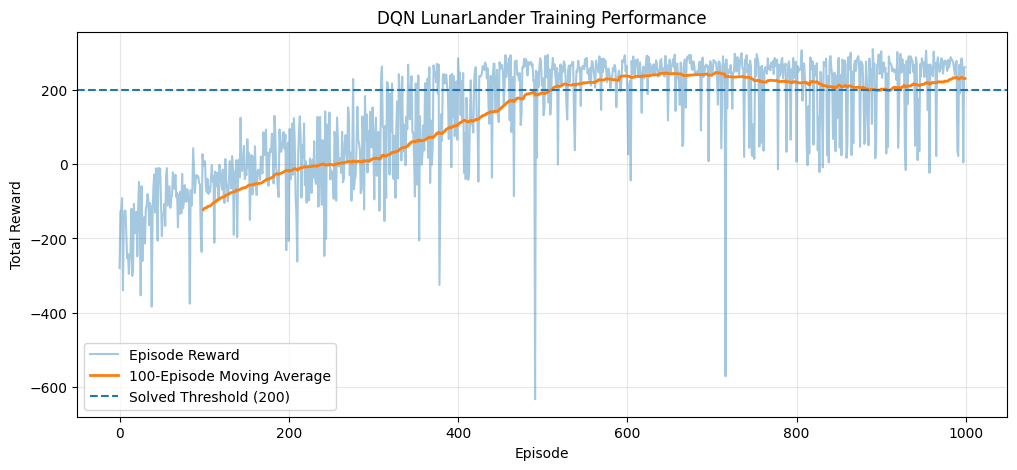

In [35]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 5))

plt.plot(
    episode_rewards,
    alpha=0.4,
    label="Episode Reward"
)

# 100-episode moving average
if len(episode_rewards) >= 100:
    moving_avg = np.convolve(
        episode_rewards,
        np.ones(100) / 100,
        mode="valid"
    )

    plt.plot(
        range(99, len(episode_rewards)),
        moving_avg,
        linewidth=2,
        label="100-Episode Moving Average"
    )

plt.axhline(
    y=200,
    linestyle="--",
    label="Solved Threshold (200)"
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("DQN LunarLander Training Performance")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [36]:
print("Number of training episodes:", len(episode_rewards))

print("Final episode reward:",
      episode_rewards[-1])

print("Best episode reward:",
      max(episode_rewards))

print("Average reward - last 100 episodes:",
      np.mean(episode_rewards[-100:]))

Number of training episodes: 1000
Final episode reward: 262.3217514807949
Best episode reward: 310.67504999877053
Average reward - last 100 episodes: 231.5442732753926


In [37]:
import os

os.makedirs("checkpoints/dqn", exist_ok=True)

In [38]:
torch.save(
    {
        "model_state_dict": policy_net.state_dict(),
        "target_state_dict": target_net.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "episode_rewards": episode_rewards,
        "episode_losses": episode_losses,
        "epsilon": epsilon
    },
    "checkpoints/dqn/dqn_final.pth"
)

print("DQN checkpoint saved.")

DQN checkpoint saved.


In [39]:
training_df = pd.DataFrame({
    "episode": range(1, len(episode_rewards) + 1),
    "reward": episode_rewards,
    "loss": episode_losses
})

training_df.to_csv(
    "dqn_training_history.csv",
    index=False
)

training_df.head()

,episode,reward,loss
0,1,-280.072929,0.465628
1,2,-127.059878,1.000518
2,3,-126.411457,1.418281
3,4,-91.218124,1.359471
4,5,-339.975800,1.253370


In [40]:
eval_env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

In [41]:
def select_greedy_action(state, model):

    state_tensor = torch.FloatTensor(
        state
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        q_values = model(state_tensor)

    return q_values.argmax(dim=1).item()

In [42]:
evaluation_rewards = []

for episode in range(100):

    state, info = eval_env.reset()

    total_reward = 0

    while True:

        action = select_greedy_action(
            state,
            policy_net
        )

        next_state, reward, terminated, truncated, info = \
            eval_env.step(action)

        total_reward += reward

        state = next_state

        if terminated or truncated:
            break

    evaluation_rewards.append(total_reward)

eval_env.close()

In [43]:
evaluation_average = np.mean(
    evaluation_rewards
)

evaluation_std = np.std(
    evaluation_rewards
)

print(
    "Average reward over 100 evaluation episodes:",
    evaluation_average
)

print(
    "Standard deviation:",
    evaluation_std
)

print(
    "Episodes >= 200:",
    sum(r >= 200 for r in evaluation_rewards)
)

Average reward over 100 evaluation episodes: 180.65110840184101
Standard deviation: 122.96314623209977
Episodes >= 200: 62


In [44]:
if evaluation_average >= 200:
    print("SUCCESS: DQN meets the ≥200 evaluation criterion.")
else:
    print("DQN has not yet reached the ≥200 evaluation criterion.")

DQN has not yet reached the ≥200 evaluation criterion.


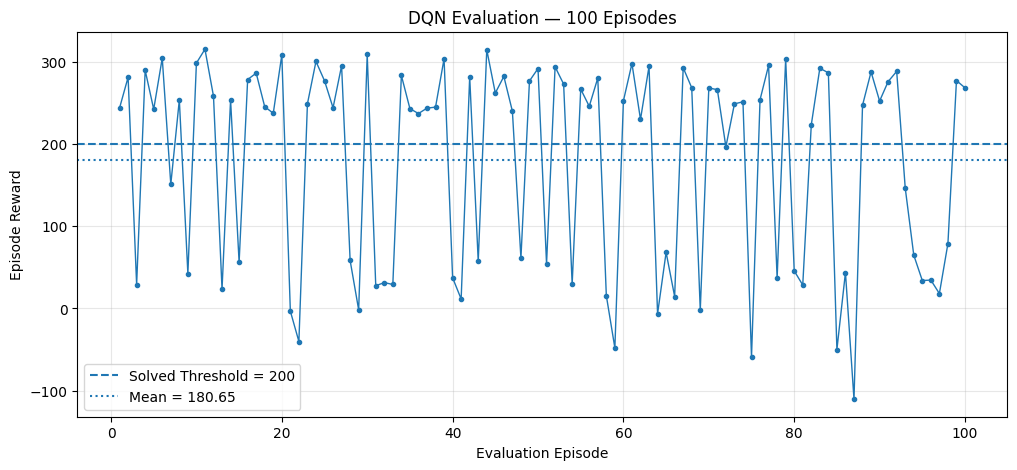

In [45]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 101),
    evaluation_rewards,
    marker=".",
    linewidth=1
)

plt.axhline(
    y=200,
    linestyle="--",
    label="Solved Threshold = 200"
)

plt.axhline(
    y=evaluation_average,
    linestyle=":",
    label=f"Mean = {evaluation_average:.2f}"
)

plt.xlabel("Evaluation Episode")
plt.ylabel("Episode Reward")
plt.title("DQN Evaluation — 100 Episodes")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [46]:
evaluation_df = pd.DataFrame({
    "evaluation_episode": range(1, 101),
    "reward": evaluation_rewards
})

evaluation_df.to_csv(
    "dqn_100_episode_evaluation.csv",
    index=False
)

print("Evaluation results saved.")

Evaluation results saved.


In [47]:
dqn_summary = pd.DataFrame({
    "metric": [
        "Evaluation episodes",
        "Average reward",
        "Standard deviation",
        "Episodes >= 200",
        "Success threshold"
    ],
    "value": [
        100,
        evaluation_average,
        evaluation_std,
        sum(r >= 200 for r in evaluation_rewards),
        200
    ]
})

dqn_summary

,metric,value
0,Evaluation episodes,100.000000
1,Average reward,180.651108
2,Standard deviation,122.963146
3,Episodes >= 200,62.000000
4,Success threshold,200.000000


In [48]:
dqn_summary.to_csv(
    "dqn_evaluation_summary.csv",
    index=False
)

In [49]:
import os

os.makedirs("checkpoints/dqn", exist_ok=True)

torch.save(
    {
        "model_state_dict": policy_net.state_dict(),
        "target_state_dict": target_net.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "episode_rewards": episode_rewards,
        "episode_losses": episode_losses,
        "epsilon": epsilon
    },
    "checkpoints/dqn/dqn_final.pth"
)

print("Final DQN checkpoint saved.")

Final DQN checkpoint saved.


In [50]:
def train_ddqn_step(
    policy_net,
    target_net,
    replay_buffer,
    optimizer
):

    if len(replay_buffer) < BATCH_SIZE:
        return None

    # Sample experience
    states, actions, rewards, next_states, dones = \
        replay_buffer.sample(BATCH_SIZE)

    states = torch.FloatTensor(states).to(device)
    actions = torch.LongTensor(actions).unsqueeze(1).to(device)

    rewards = torch.FloatTensor(
        rewards
    ).unsqueeze(1).to(device)

    next_states = torch.FloatTensor(
        next_states
    ).to(device)

    dones = torch.FloatTensor(
        dones
    ).unsqueeze(1).to(device)

    # ------------------------------------------------
    # Current Q-values from POLICY network
    # ------------------------------------------------

    current_q = policy_net(states).gather(
        1,
        actions
    )

    # ------------------------------------------------
    # DOUBLE DQN TARGET
    # ------------------------------------------------

    with torch.no_grad():

        # Step 1:
        # Policy network selects the best action
        next_actions = policy_net(
            next_states
        ).argmax(
            dim=1,
            keepdim=True
        )

        # Step 2:
        # Target network evaluates that action
        next_q = target_net(
            next_states
        ).gather(
            1,
            next_actions
        )

        # Step 3:
        # Bellman target
        target_q = rewards + (
            GAMMA * next_q * (1 - dones)
        )

    # Huber loss
    loss = F.smooth_l1_loss(
        current_q,
        target_q
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    return loss.item()

In [51]:
ddqn_policy_net = DQN(state_size, action_size).to(device)

ddqn_target_net = DQN(state_size, action_size).to(device)

ddqn_target_net.load_state_dict(
    ddqn_policy_net.state_dict()
)

ddqn_target_net.eval()

ddqn_optimizer = torch.optim.Adam(
    ddqn_policy_net.parameters(),
    lr=LEARNING_RATE
)

ddqn_replay_buffer = ReplayBuffer(
    capacity=100000
)

print("DDQN initialized.")

DDQN initialized.


In [52]:
ddqn_episode_rewards = []
ddqn_episode_losses = []

ddqn_epsilon = EPSILON_START

# Re-initialize environment for DDQN training
# (The previous one was closed after DQN training)

env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

for episode in range(1, NUM_EPISODES + 1):

    state, info = env.reset()

    total_reward = 0
    losses = []

    while True:

        # Choose action using epsilon-greedy policy with DDQN policy network
        action = select_action_with_dqn(
            state,
            ddqn_policy_net,
            ddqn_epsilon
        )

        # Interact with LunarLander
        next_state, reward, terminated, truncated, info = \
            env.step(action)

        done = terminated or truncated

        # Store REAL experience in DDQN replay buffer
        ddqn_replay_buffer.add(
            state,
            action,
            reward,
            next_state,
            done
        )

        # Train DDQN
        loss = train_ddqn_step(
            ddqn_policy_net,
            ddqn_target_net,
            ddqn_replay_buffer,
            ddqn_optimizer
        )

        if loss is not None:
            losses.append(loss)

        state = next_state

        total_reward += reward

        if done:
            break

    # Decay epsilon
    ddqn_epsilon = max(
        EPSILON_END,
        ddqn_epsilon * EPSILON_DECAY
    )

    # Update target network (copy weights from policy network)
    if episode % TARGET_UPDATE_FREQUENCY == 0:

        ddqn_target_net.load_state_dict(
            ddqn_policy_net.state_dict()
        )

    ddqn_episode_rewards.append(total_reward)

    if losses:
        ddqn_episode_losses.append(
            np.mean(losses)
        )
    else:
        ddqn_episode_losses.append(np.nan)

    if episode % 10 == 0:

        avg_reward = np.mean(
            ddqn_episode_rewards[-10:]
        )

        print(
            f"DDQN Episode {episode:4d} | "
            f"Reward: {total_reward:8.2f} | "
            f"Avg(10): {avg_reward:8.2f} | "
            f"Epsilon: {ddqn_epsilon:.3f}"
        )

env.close()


DDQN Episode   10 | Reward:  -233.15 | Avg(10):  -172.32 | Epsilon: 0.951
DDQN Episode   20 | Reward:  -337.37 | Avg(10):  -211.06 | Epsilon: 0.905
DDQN Episode   30 | Reward:  -108.29 | Avg(10):  -188.17 | Epsilon: 0.860
DDQN Episode   40 | Reward:   -85.63 | Avg(10):  -120.57 | Epsilon: 0.818
DDQN Episode   50 | Reward:   -67.42 | Avg(10):   -88.69 | Epsilon: 0.778
DDQN Episode   60 | Reward:  -230.75 | Avg(10):   -94.58 | Epsilon: 0.740
DDQN Episode   70 | Reward:   -76.46 | Avg(10):   -86.62 | Epsilon: 0.704
DDQN Episode   80 | Reward:   -65.05 | Avg(10):  -100.67 | Epsilon: 0.670
DDQN Episode   90 | Reward:   -67.01 | Avg(10):   -85.10 | Epsilon: 0.637
DDQN Episode  100 | Reward:   -35.82 | Avg(10):   -42.27 | Epsilon: 0.606
DDQN Episode  110 | Reward:   -72.49 | Avg(10):   -41.31 | Epsilon: 0.576
DDQN Episode  120 | Reward:   -40.29 | Avg(10):   -38.14 | Epsilon: 0.548
DDQN Episode  130 | Reward:   -30.60 | Avg(10):   -36.03 | Epsilon: 0.521
DDQN Episode  140 | Reward:   -75.11 |

In [53]:
print("DDQN episodes trained:", len(ddqn_episode_rewards))
print("Best training reward:", max(ddqn_episode_rewards))
print("Last episode reward:", ddqn_episode_rewards[-1])
print(
    "Last 100 episode average:",
    np.mean(ddqn_episode_rewards[-100:])
)

DDQN episodes trained: 1000
Best training reward: 314.2502783885153
Last episode reward: 24.363187333296665
Last 100 episode average: 1.9516509790445877


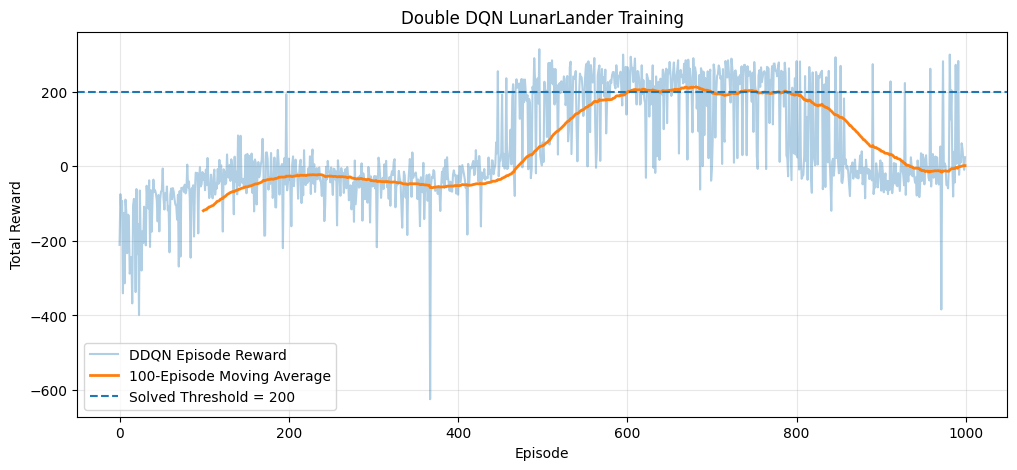

In [54]:
plt.figure(figsize=(12, 5))

plt.plot(
    ddqn_episode_rewards,
    alpha=0.35,
    label="DDQN Episode Reward"
)

if len(ddqn_episode_rewards) >= 100:

    moving_avg = np.convolve(
        ddqn_episode_rewards,
        np.ones(100) / 100,
        mode="valid"
    )

    plt.plot(
        range(99, len(ddqn_episode_rewards)),
        moving_avg,
        linewidth=2,
        label="100-Episode Moving Average"
    )

plt.axhline(
    y=200,
    linestyle="--",
    label="Solved Threshold = 200"
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Double DQN LunarLander Training")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [55]:
ddqn_eval_env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

ddqn_evaluation_rewards = []

for episode in range(100):

    state, info = ddqn_eval_env.reset()

    total_reward = 0

    while True:

        # Greedy action — no exploration during evaluation
        action = select_greedy_action(
            state,
            ddqn_policy_net
        )

        next_state, reward, terminated, truncated, info = \
            ddqn_eval_env.step(action)

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    ddqn_evaluation_rewards.append(total_reward)

ddqn_eval_env.close()

In [56]:
ddqn_average = np.mean(
    ddqn_evaluation_rewards
)

ddqn_std = np.std(
    ddqn_evaluation_rewards
)

ddqn_solved = sum(
    reward >= 200
    for reward in ddqn_evaluation_rewards
)

print("DDQN Evaluation Results")
print("-----------------------")
print("Average reward:", ddqn_average)
print("Standard deviation:", ddqn_std)
print("Episodes >= 200:", ddqn_solved)

DDQN Evaluation Results
-----------------------
Average reward: -48.993888746443965
Standard deviation: 75.1367641816592
Episodes >= 200: 4


In [57]:
ddqn_evaluation_df = pd.DataFrame({
    "evaluation_episode": range(1, 101),
    "reward": ddqn_evaluation_rewards
})

ddqn_evaluation_df.to_csv(
    "ddqn_100_episode_evaluation.csv",
    index=False
)

print("DDQN evaluation data saved.")

DDQN evaluation data saved.


In [58]:
os.makedirs("checkpoints/ddqn", exist_ok=True)

torch.save(
    {
        "model_state_dict": ddqn_policy_net.state_dict(),
        "target_state_dict": ddqn_target_net.state_dict(),
        "optimizer_state_dict": ddqn_optimizer.state_dict(),
        "episode_rewards": ddqn_episode_rewards,
        "episode_losses": ddqn_episode_losses,
        "epsilon": ddqn_epsilon
    },
    "checkpoints/ddqn/ddqn_final.pth"
)

print("DDQN final checkpoint saved.")

DDQN final checkpoint saved.


In [59]:
ddqn_eval_env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

ddqn_evaluation_rewards = []

for episode in range(100):

    state, info = ddqn_eval_env.reset()
    total_reward = 0

    while True:

        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)

        with torch.no_grad():
            q_values = ddqn_policy_net(state_tensor)

        action = q_values.argmax(dim=1).item()

        next_state, reward, terminated, truncated, info = \
            ddqn_eval_env.step(action)

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    ddqn_evaluation_rewards.append(total_reward)

ddqn_eval_env.close()

ddqn_average = np.mean(ddqn_evaluation_rewards)
ddqn_std = np.std(ddqn_evaluation_rewards)
ddqn_solved = sum(r >= 200 for r in ddqn_evaluation_rewards)

print("=" * 55)
print("DDQN — 100 EPISODE EVALUATION")
print("=" * 55)
print(f"Average Reward     : {ddqn_average:.2f}")
print(f"Standard Deviation : {ddqn_std:.2f}")
print(f"Episodes >= 200    : {ddqn_solved}/100")
print(f"Minimum Reward     : {min(ddqn_evaluation_rewards):.2f}")
print(f"Maximum Reward     : {max(ddqn_evaluation_rewards):.2f}")

if ddqn_average >= 200:
    print("\nSUCCESS: DDQN satisfies the assignment criterion.")
else:
    print("\nDDQN does not yet satisfy the assignment criterion.")

DDQN — 100 EPISODE EVALUATION
Average Reward     : -22.00
Standard Deviation : 105.07
Episodes >= 200    : 10/100
Minimum Reward     : -192.17
Maximum Reward     : 303.13

DDQN does not yet satisfy the assignment criterion.


In [60]:
ddqn_evaluation_df = pd.DataFrame({
    "evaluation_episode": range(1, 101),
    "reward": ddqn_evaluation_rewards
})

ddqn_evaluation_df.to_csv(
    "ddqn_100_episode_evaluation.csv",
    index=False
)

print("Saved: ddqn_100_episode_evaluation.csv")

Saved: ddqn_100_episode_evaluation.csv


In [61]:
import os
import torch

os.makedirs("checkpoints/ddqn", exist_ok=True)

torch.save({
    "model_state_dict": ddqn_policy_net.state_dict(),
    "target_state_dict": ddqn_target_net.state_dict(),
    "optimizer_state_dict": ddqn_optimizer.state_dict(),
    "episode_rewards": ddqn_episode_rewards,
    "episode_losses": ddqn_episode_losses,
    "epsilon": ddqn_epsilon
}, "checkpoints/ddqn/ddqn_final.pth")

print("Saved: checkpoints/ddqn/ddqn_final.pth")

Saved: checkpoints/ddqn/ddqn_final.pth


In [62]:
import random
import numpy as np
import torch
import gymnasium as gym

SEEDS = [42, 123, 2026]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

print("Seeds:", SEEDS)

Seeds: [42, 123, 2026]


In [63]:
SEEDS = [42, 123, 2026]

In [64]:
NUM_EPISODES = 1000

BATCH_SIZE = 64
GAMMA = 0.99

EPSILON_START = 1.0
EPSILON_END = 0.01
EPSILON_DECAY = 0.995

LEARNING_RATE = 1e-3
TARGET_UPDATE_FREQUENCY = 10

REPLAY_CAPACITY = 100000

print("Training configuration ready.")

Training configuration ready.


In [65]:
import os
import random
import numpy as np
import torch
import torch.nn.functional as F
import gymnasium as gym

# Store results
dqn_seed_results = {}

os.makedirs("checkpoints/dqn/seeds", exist_ok=True)

for seed in SEEDS:

    print("\n" + "=" * 70)
    print(f"STARTING DQN TRAINING — SEED {seed}")
    print("=" * 70)

    # --------------------------------------------------
    # Set random seeds
    # --------------------------------------------------
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # --------------------------------------------------
    # Environment
    # --------------------------------------------------
    env = gym.make(
        "LunarLander-v3",
        continuous=False,
        gravity=-10.0,
        enable_wind=False,
        wind_power=15.0,
        turbulence_power=1.5
    )

    # Seed environment
    env.reset(seed=seed)
    env.action_space.seed(seed)

    # --------------------------------------------------
    # Fresh DQN networks
    # --------------------------------------------------
    seed_policy_net = DQN().to(device)
    seed_target_net = DQN().to(device)

    seed_target_net.load_state_dict(
        seed_policy_net.state_dict()
    )

    seed_target_net.eval()

    # --------------------------------------------------
    # Optimizer
    # --------------------------------------------------
    seed_optimizer = torch.optim.Adam(
        seed_policy_net.parameters(),
        lr=LEARNING_RATE
    )

    # --------------------------------------------------
    # Fresh replay buffer
    # --------------------------------------------------
    seed_replay_buffer = ReplayBuffer(
        capacity=REPLAY_CAPACITY
    )

    # --------------------------------------------------
    # Training history
    # --------------------------------------------------
    seed_episode_rewards = []
    seed_episode_losses = []

    epsilon = EPSILON_START

    # --------------------------------------------------
    # Training
    # --------------------------------------------------
    for episode in range(1, NUM_EPISODES + 1):

        state, info = env.reset()

        total_reward = 0
        losses = []

        while True:

            # Epsilon-greedy action
            action = select_action_with_dqn(
                state,
                seed_policy_net,
                epsilon
            )

            # Environment interaction
            next_state, reward, terminated, truncated, info = \
                env.step(action)

            done = terminated or truncated

            # Store real transition
            seed_replay_buffer.add(
                state,
                action,
                reward,
                next_state,
                done
            )

            # -----------------------------
            # DQN training step
            # -----------------------------
            if len(seed_replay_buffer) >= BATCH_SIZE:

                states, actions, rewards, next_states, dones = \
                    seed_replay_buffer.sample(BATCH_SIZE)

                states = torch.FloatTensor(states).to(device)
                actions = torch.LongTensor(actions).unsqueeze(1).to(device)
                rewards = torch.FloatTensor(rewards).unsqueeze(1).to(device)
                next_states = torch.FloatTensor(next_states).to(device)
                dones = torch.FloatTensor(dones).unsqueeze(1).to(device)

                # Current Q-values
                current_q = seed_policy_net(states).gather(
                    1,
                    actions
                )

                # Target Q-values
                with torch.no_grad():

                    next_q = seed_target_net(
                        next_states
                    ).max(
                        dim=1,
                        keepdim=True
                    )[0]

                    target_q = rewards + \
                        GAMMA * next_q * (1 - dones)

                # Huber loss
                loss = F.smooth_l1_loss(
                    current_q,
                    target_q
                )

                # Optimization
                seed_optimizer.zero_grad()
                loss.backward()
                seed_optimizer.step()

                losses.append(loss.item())

            state = next_state
            total_reward += reward

            if done:
                break

        # --------------------------------------------------
        # Epsilon decay
        # --------------------------------------------------
        epsilon = max(
            EPSILON_END,
            epsilon * EPSILON_DECAY
        )

        # --------------------------------------------------
        # Target network update
        # --------------------------------------------------
        if episode % TARGET_UPDATE_FREQUENCY == 0:

            seed_target_net.load_state_dict(
                seed_policy_net.state_dict()
            )

        # --------------------------------------------------
        # Save history
        # --------------------------------------------------
        seed_episode_rewards.append(total_reward)

        if losses:
            seed_episode_losses.append(
                np.mean(losses)
            )
        else:
            seed_episode_losses.append(np.nan)

        # --------------------------------------------------
        # Progress
        # --------------------------------------------------
        if episode % 100 == 0:

            avg_reward = np.mean(
                seed_episode_rewards[-100:]
            )

            print(
                f"Seed {seed} | "
                f"Episode {episode:4d} | "
                f"Last Reward: {total_reward:8.2f} | "
                f"Avg(100): {avg_reward:8.2f} | "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    # --------------------------------------------------
    # Store results
    # --------------------------------------------------
    dqn_seed_results[seed] = {
        "rewards": seed_episode_rewards,
        "losses": seed_episode_losses,
        "policy_net": seed_policy_net,
        "target_net": seed_target_net
    }

    # --------------------------------------------------
    # Save checkpoint
    # --------------------------------------------------
    torch.save({

        "seed": seed,

        "model_state_dict":
            seed_policy_net.state_dict(),

        "target_state_dict":
            seed_target_net.state_dict(),

        "optimizer_state_dict":
            seed_optimizer.state_dict(),

        "episode_rewards":
            seed_episode_rewards,

        "episode_losses":
            seed_episode_losses,

        "epsilon":
            epsilon

    }, f"checkpoints/dqn/seeds/dqn_seed_{seed}.pth")

    # --------------------------------------------------
    # Save CSV
    # --------------------------------------------------
    seed_df = pd.DataFrame({

        "episode":
            range(1, NUM_EPISODES + 1),

        "reward":
            seed_episode_rewards,

        "loss":
            seed_episode_losses

    })

    seed_df.to_csv(
        f"checkpoints/dqn/seeds/dqn_seed_{seed}_history.csv",
        index=False
    )

    print(
        f"Completed DQN seed {seed}."
    )

print("\n" + "=" * 70)
print("ALL THREE DQN SEEDS COMPLETED")
print("=" * 70)


STARTING DQN TRAINING — SEED 42
Seed 42 | Episode  100 | Last Reward:   -25.48 | Avg(100):  -124.64 | Epsilon: 0.606
Seed 42 | Episode  200 | Last Reward:    42.93 | Avg(100):   -38.99 | Epsilon: 0.367
Seed 42 | Episode  300 | Last Reward:   142.73 | Avg(100):   -15.42 | Epsilon: 0.222
Seed 42 | Episode  400 | Last Reward:   214.92 | Avg(100):   116.97 | Epsilon: 0.135
Seed 42 | Episode  500 | Last Reward:   246.86 | Avg(100):   194.01 | Epsilon: 0.082
Seed 42 | Episode  600 | Last Reward:   245.96 | Avg(100):   227.10 | Epsilon: 0.049
Seed 42 | Episode  700 | Last Reward:   298.62 | Avg(100):   227.24 | Epsilon: 0.030
Seed 42 | Episode  800 | Last Reward:   255.77 | Avg(100):   210.70 | Epsilon: 0.018
Seed 42 | Episode  900 | Last Reward:   254.94 | Avg(100):   243.81 | Epsilon: 0.011
Seed 42 | Episode 1000 | Last Reward:   267.42 | Avg(100):   237.92 | Epsilon: 0.010
Completed DQN seed 42.

STARTING DQN TRAINING — SEED 123
Seed 123 | Episode  100 | Last Reward:   -18.56 | Avg(100): 

In [66]:
# ============================================================
# 3-SEED DOUBLE DQN EXPERIMENT
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn.functional as F
import gymnasium as gym

ddqn_seed_results = {}

os.makedirs("checkpoints/ddqn/seeds", exist_ok=True)

for seed in SEEDS:

    print("\n" + "=" * 70)
    print(f"STARTING DDQN TRAINING — SEED {seed}")
    print("=" * 70)

    # --------------------------------------------------
    # Set random seeds
    # --------------------------------------------------
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # --------------------------------------------------
    # Environment
    # --------------------------------------------------
    env = gym.make(
        "LunarLander-v3",
        continuous=False,
        gravity=-10.0,
        enable_wind=False,
        wind_power=15.0,
        turbulence_power=1.5
    )

    env.reset(seed=seed)
    env.action_space.seed(seed)

    # --------------------------------------------------
    # Fresh DDQN networks
    # --------------------------------------------------
    seed_policy_net = DQN().to(device)
    seed_target_net = DQN().to(device)

    seed_target_net.load_state_dict(
        seed_policy_net.state_dict()
    )

    seed_target_net.eval()

    # --------------------------------------------------
    # Optimizer
    # --------------------------------------------------
    seed_optimizer = torch.optim.Adam(
        seed_policy_net.parameters(),
        lr=LEARNING_RATE
    )

    # --------------------------------------------------
    # Fresh replay buffer
    # --------------------------------------------------
    seed_replay_buffer = ReplayBuffer(
        capacity=REPLAY_CAPACITY
    )

    # --------------------------------------------------
    # Training history
    # --------------------------------------------------
    seed_episode_rewards = []
    seed_episode_losses = []

    epsilon = EPSILON_START

    # --------------------------------------------------
    # Training
    # --------------------------------------------------
    for episode in range(1, NUM_EPISODES + 1):

        state, info = env.reset()

        total_reward = 0
        losses = []

        while True:

            # Epsilon-greedy action
            action = select_action_with_dqn(
                state,
                seed_policy_net,
                epsilon
            )

            # Environment interaction
            next_state, reward, terminated, truncated, info = \
                env.step(action)

            done = terminated or truncated

            # Store real transition
            seed_replay_buffer.add(
                state,
                action,
                reward,
                next_state,
                done
            )

            # --------------------------------------------------
            # DOUBLE DQN TRAINING STEP
            # --------------------------------------------------
            if len(seed_replay_buffer) >= BATCH_SIZE:

                states, actions, rewards, next_states, dones = \
                    seed_replay_buffer.sample(BATCH_SIZE)

                states = torch.FloatTensor(states).to(device)
                actions = torch.LongTensor(actions).unsqueeze(1).to(device)
                rewards = torch.FloatTensor(rewards).unsqueeze(1).to(device)
                next_states = torch.FloatTensor(next_states).to(device)
                dones = torch.FloatTensor(dones).unsqueeze(1).to(device)

                # Current Q-value from POLICY network
                current_q = seed_policy_net(states).gather(
                    1,
                    actions
                )

                # --------------------------------------------------
                # DOUBLE DQN TARGET
                # --------------------------------------------------
                with torch.no_grad():

                    # Step 1:
                    # Policy network SELECTS the best next action
                    next_actions = seed_policy_net(
                        next_states
                    ).argmax(
                        dim=1,
                        keepdim=True
                    )

                    # Step 2:
                    # Target network EVALUATES that action
                    next_q = seed_target_net(
                        next_states
                    ).gather(
                        1,
                        next_actions
                    )

                    target_q = rewards + \
                        GAMMA * next_q * (1 - dones)

                # --------------------------------------------------
                # Huber loss
                # --------------------------------------------------
                loss = F.smooth_l1_loss(
                    current_q,
                    target_q
                )

                # --------------------------------------------------
                # Optimization
                # --------------------------------------------------
                seed_optimizer.zero_grad()
                loss.backward()
                seed_optimizer.step()

                losses.append(loss.item())

            state = next_state
            total_reward += reward

            if done:
                break

        # --------------------------------------------------
        # Epsilon decay
        # --------------------------------------------------
        epsilon = max(
            EPSILON_END,
            epsilon * EPSILON_DECAY
        )

        # --------------------------------------------------
        # Target network update
        # --------------------------------------------------
        if episode % TARGET_UPDATE_FREQUENCY == 0:

            seed_target_net.load_state_dict(
                seed_policy_net.state_dict()
            )

        # --------------------------------------------------
        # Save history
        # --------------------------------------------------
        seed_episode_rewards.append(total_reward)

        if losses:
            seed_episode_losses.append(
                np.mean(losses)
            )
        else:
            seed_episode_losses.append(np.nan)

        # --------------------------------------------------
        # Progress
        # --------------------------------------------------
        if episode % 100 == 0:

            avg_reward = np.mean(
                seed_episode_rewards[-100:]
            )

            print(
                f"Seed {seed} | "
                f"Episode {episode:4d} | "
                f"Last Reward: {total_reward:8.2f} | "
                f"Avg(100): {avg_reward:8.2f} | "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    # --------------------------------------------------
    # Store results
    # --------------------------------------------------
    ddqn_seed_results[seed] = {
        "rewards": seed_episode_rewards,
        "losses": seed_episode_losses,
        "policy_net": seed_policy_net,
        "target_net": seed_target_net
    }

    # --------------------------------------------------
    # Save checkpoint
    # --------------------------------------------------
    torch.save({

        "seed": seed,

        "model_state_dict":
            seed_policy_net.state_dict(),

        "target_state_dict":
            seed_target_net.state_dict(),

        "optimizer_state_dict":
            seed_optimizer.state_dict(),

        "episode_rewards":
            seed_episode_rewards,

        "episode_losses":
            seed_episode_losses,

        "epsilon":
            epsilon

    }, f"checkpoints/ddqn/seeds/ddqn_seed_{seed}.pth")

    # --------------------------------------------------
    # Save training history
    # --------------------------------------------------
    seed_df = pd.DataFrame({

        "episode":
            range(1, NUM_EPISODES + 1),

        "reward":
            seed_episode_rewards,

        "loss":
            seed_episode_losses

    })

    seed_df.to_csv(
        f"checkpoints/ddqn/seeds/ddqn_seed_{seed}_history.csv",
        index=False
    )

    print(
        f"Completed DDQN seed {seed}."
    )

print("\n" + "=" * 70)
print("ALL THREE DDQN SEEDS COMPLETED")
print("=" * 70)


STARTING DDQN TRAINING — SEED 42
Seed 42 | Episode  100 | Last Reward:    85.73 | Avg(100):  -112.12 | Epsilon: 0.606
Seed 42 | Episode  200 | Last Reward:  -121.03 | Avg(100):   -33.53 | Epsilon: 0.367
Seed 42 | Episode  300 | Last Reward:   -29.80 | Avg(100):   -75.01 | Epsilon: 0.222
Seed 42 | Episode  400 | Last Reward:   214.17 | Avg(100):    63.67 | Epsilon: 0.135
Seed 42 | Episode  500 | Last Reward:   277.14 | Avg(100):   213.33 | Epsilon: 0.082
Seed 42 | Episode  600 | Last Reward:   247.73 | Avg(100):   229.01 | Epsilon: 0.049
Seed 42 | Episode  700 | Last Reward:   181.04 | Avg(100):   212.28 | Epsilon: 0.030
Seed 42 | Episode  800 | Last Reward:   240.61 | Avg(100):   219.76 | Epsilon: 0.018
Seed 42 | Episode  900 | Last Reward:   258.36 | Avg(100):   181.17 | Epsilon: 0.011
Seed 42 | Episode 1000 | Last Reward:    12.05 | Avg(100):    22.88 | Epsilon: 0.010
Completed DDQN seed 42.

STARTING DDQN TRAINING — SEED 123
Seed 123 | Episode  100 | Last Reward:     4.88 | Avg(100

In [67]:
# ============================================================
# 100-EPISODE EVALUATION — ALL 6 TRAINED AGENTS
# ============================================================

evaluation_results = {}

def evaluate_agent(policy_net, seed, algorithm):

    eval_env = gym.make(
        "LunarLander-v3",
        continuous=False,
        gravity=-10.0,
        enable_wind=False,
        wind_power=15.0,
        turbulence_power=1.5
    )

    rewards = []

    for episode in range(100):

        state, info = eval_env.reset(
            seed=seed + episode
        )

        total_reward = 0

        while True:

            state_tensor = torch.FloatTensor(
                state
            ).unsqueeze(0).to(device)

            with torch.no_grad():
                q_values = policy_net(
                    state_tensor
                )

            # Greedy action — no exploration
            action = q_values.argmax(
                dim=1
            ).item()

            next_state, reward, terminated, truncated, info = \
                eval_env.step(action)

            total_reward += reward
            state = next_state

            if terminated or truncated:
                break

        rewards.append(total_reward)

    eval_env.close()

    return {
        "rewards": rewards,
        "mean": np.mean(rewards),
        "std": np.std(rewards),
        "min": np.min(rewards),
        "max": np.max(rewards),
        "solved": sum(r >= 200 for r in rewards)
    }


# ============================================================
# DQN EVALUATION
# ============================================================

for seed in SEEDS:

    print("\n" + "=" * 60)
    print(f"EVALUATING DQN — SEED {seed}")
    print("=" * 60)

    model = dqn_seed_results[seed]["policy_net"]

    result = evaluate_agent(
        model,
        seed,
        "DQN"
    )

    evaluation_results[
        ("DQN", seed)
    ] = result

    print(
        f"Mean Reward       : {result['mean']:.2f}"
    )

    print(
        f"Std. Deviation    : {result['std']:.2f}"
    )

    print(
        f"Episodes >= 200   : {result['solved']}/100"
    )

    print(
        f"Minimum Reward    : {result['min']:.2f}"
    )

    print(
        f"Maximum Reward    : {result['max']:.2f}"
    )


# ============================================================
# DDQN EVALUATION
# ============================================================

for seed in SEEDS:

    print("\n" + "=" * 60)
    print(f"EVALUATING DDQN — SEED {seed}")
    print("=" * 60)

    model = ddqn_seed_results[seed]["policy_net"]

    result = evaluate_agent(
        model,
        seed,
        "DDQN"
    )

    evaluation_results[
        ("DDQN", seed)
    ] = result

    print(
        f"Mean Reward       : {result['mean']:.2f}"
    )

    print(
        f"Std. Deviation    : {result['std']:.2f}"
    )

    print(
        f"Episodes >= 200   : {result['solved']}/100"
    )

    print(
        f"Minimum Reward    : {result['min']:.2f}"
    )

    print(
        f"Maximum Reward    : {result['max']:.2f}"
    )


print("\n" + "=" * 60)
print("ALL 6 EVALUATIONS COMPLETED")
print("=" * 60)


EVALUATING DQN — SEED 42
Mean Reward       : 255.05
Std. Deviation    : 63.43
Episodes >= 200   : 90/100
Minimum Reward    : -15.74
Maximum Reward    : 313.02

EVALUATING DQN — SEED 123
Mean Reward       : 239.29
Std. Deviation    : 75.18
Episodes >= 200   : 82/100
Minimum Reward    : 18.86
Maximum Reward    : 321.17

EVALUATING DQN — SEED 2026
Mean Reward       : 129.69
Std. Deviation    : 151.71
Episodes >= 200   : 52/100
Minimum Reward    : -235.21
Maximum Reward    : 309.83

EVALUATING DDQN — SEED 42
Mean Reward       : 102.98
Std. Deviation    : 130.08
Episodes >= 200   : 34/100
Minimum Reward    : -234.46
Maximum Reward    : 300.15

EVALUATING DDQN — SEED 123
Mean Reward       : 168.23
Std. Deviation    : 129.76
Episodes >= 200   : 55/100
Minimum Reward    : -251.15
Maximum Reward    : 310.70

EVALUATING DDQN — SEED 2026
Mean Reward       : 164.59
Std. Deviation    : 147.16
Episodes >= 200   : 61/100
Minimum Reward    : -350.80
Maximum Reward    : 305.58

ALL 6 EVALUATIONS COMPL

In [68]:
# ============================================================
# FINAL DQN vs DDQN STATISTICS ACROSS 3 SEEDS
# ============================================================

dqn_eval_means = [
    evaluation_results[("DQN", seed)]["mean"]
    for seed in SEEDS
]

ddqn_eval_means = [
    evaluation_results[("DDQN", seed)]["mean"]
    for seed in SEEDS
]

dqn_cross_seed_mean = np.mean(dqn_eval_means)
dqn_cross_seed_std = np.std(dqn_eval_means, ddof=1)

ddqn_cross_seed_mean = np.mean(ddqn_eval_means)
ddqn_cross_seed_std = np.std(ddqn_eval_means, ddof=1)

print("=" * 60)
print("FINAL 3-SEED EVALUATION SUMMARY")
print("=" * 60)

print("\nDQN")
print(f"Seed means          : {[round(x, 2) for x in dqn_eval_means]}")
print(f"Mean across seeds   : {dqn_cross_seed_mean:.2f}")
print(f"Std across seeds    : {dqn_cross_seed_std:.2f}")

print("\nDDQN")
print(f"Seed means          : {[round(x, 2) for x in ddqn_eval_means]}")
print(f"Mean across seeds   : {ddqn_cross_seed_mean:.2f}")
print(f"Std across seeds    : {ddqn_cross_seed_std:.2f}")

FINAL 3-SEED EVALUATION SUMMARY

DQN
Seed means          : [np.float64(255.05), np.float64(239.29), np.float64(129.69)]
Mean across seeds   : 208.01
Std across seeds    : 68.28

DDQN
Seed means          : [np.float64(102.98), np.float64(168.23), np.float64(164.59)]
Mean across seeds   : 145.27
Std across seeds    : 36.67


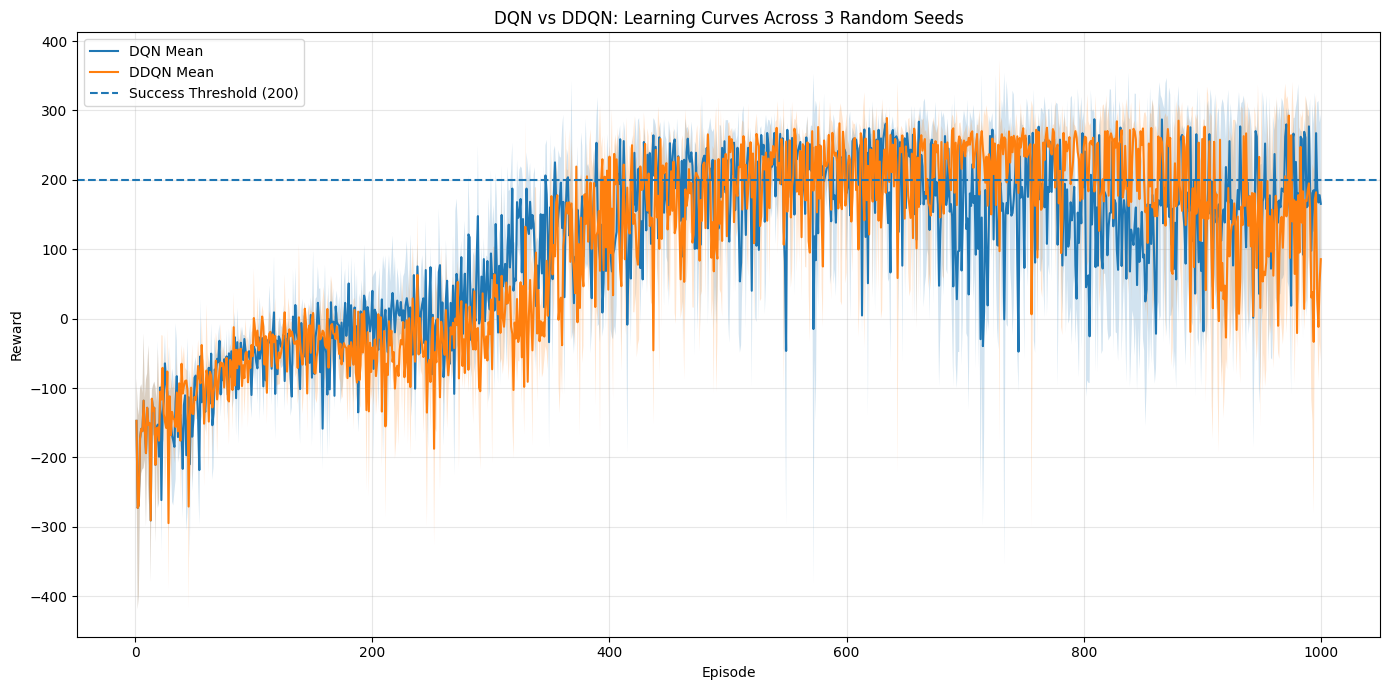

In [69]:
import matplotlib.pyplot as plt

# Convert training histories into matrices
dqn_rewards = np.array([
    dqn_seed_results[seed]["rewards"]
    for seed in SEEDS
])

ddqn_rewards = np.array([
    ddqn_seed_results[seed]["rewards"]
    for seed in SEEDS
])

episodes = np.arange(1, NUM_EPISODES + 1)

# Mean and standard deviation
dqn_mean = np.mean(dqn_rewards, axis=0)
dqn_std = np.std(dqn_rewards, axis=0)

ddqn_mean = np.mean(ddqn_rewards, axis=0)
ddqn_std = np.std(ddqn_rewards, axis=0)

# Plot
plt.figure(figsize=(14, 7))

plt.plot(
    episodes,
    dqn_mean,
    label="DQN Mean"
)

plt.fill_between(
    episodes,
    dqn_mean - dqn_std,
    dqn_mean + dqn_std,
    alpha=0.2
)

plt.plot(
    episodes,
    ddqn_mean,
    label="DDQN Mean"
)

plt.fill_between(
    episodes,
    ddqn_mean - ddqn_std,
    ddqn_mean + ddqn_std,
    alpha=0.2
)

plt.axhline(
    200,
    linestyle="--",
    label="Success Threshold (200)"
)

plt.xlabel("Episode")
plt.ylabel("Reward")

plt.title(
    "DQN vs DDQN: Learning Curves Across 3 Random Seeds"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "dqn_vs_ddqn_3seed_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
import os
import torch

os.makedirs("checkpoints/app", exist_ok=True)

# Create a completely fresh untrained DQN
untrained_net = DQN().to(device)

torch.save(
    {
        "model_state_dict": untrained_net.state_dict(),
        "stage": "untrained",
        "episode": 0
    },
    "checkpoints/app/dqn_untrained.pth"
)

print("Saved:")
print("checkpoints/app/dqn_untrained.pth")

Saved:
checkpoints/app/dqn_untrained.pth


In [71]:
import shutil

source = "checkpoints/dqn/seeds/dqn_seed_2026.pth"
destination = "checkpoints/app/dqn_final.pth"

shutil.copy2(source, destination)

print("Saved:")
print(destination)

Saved:
checkpoints/app/dqn_final.pth


In [72]:
# ============================================================
# CHECKPOINT TRAINING RUN
# Saves:
#   Episode 0   -> already saved
#   Episode 500 -> dqn_mid.pth
#   Episode 1000 -> dqn_final_checkpoint.pth
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn.functional as F
import gymnasium as gym
import pandas as pd

CHECKPOINT_SEED = 2026

# ------------------------------------------------------------
# Set seed
# ------------------------------------------------------------
random.seed(CHECKPOINT_SEED)
np.random.seed(CHECKPOINT_SEED)
torch.manual_seed(CHECKPOINT_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CHECKPOINT_SEED)

# ------------------------------------------------------------
# Environment
# ------------------------------------------------------------
checkpoint_env = gym.make(
    "LunarLander-v3",
    continuous=False,
    gravity=-10.0,
    enable_wind=False,
    wind_power=15.0,
    turbulence_power=1.5
)

checkpoint_env.reset(seed=CHECKPOINT_SEED)
checkpoint_env.action_space.seed(CHECKPOINT_SEED)

# ------------------------------------------------------------
# Fresh DQN
# ------------------------------------------------------------
checkpoint_policy_net = DQN().to(device)
checkpoint_target_net = DQN().to(device)

checkpoint_target_net.load_state_dict(
    checkpoint_policy_net.state_dict()
)

checkpoint_target_net.eval()

checkpoint_optimizer = torch.optim.Adam(
    checkpoint_policy_net.parameters(),
    lr=LEARNING_RATE
)

checkpoint_replay_buffer = ReplayBuffer(
    capacity=REPLAY_CAPACITY
)

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------
checkpoint_rewards = []
checkpoint_losses = []

epsilon = EPSILON_START

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------
for episode in range(1, NUM_EPISODES + 1):

    state, info = checkpoint_env.reset()

    total_reward = 0
    losses = []

    while True:

        # Epsilon-greedy action
        action = select_action_with_dqn(
            state,
            checkpoint_policy_net,
            epsilon
        )

        # Environment interaction
        next_state, reward, terminated, truncated, info = \
            checkpoint_env.step(action)

        done = terminated or truncated

        # Store transition
        checkpoint_replay_buffer.add(
            state,
            action,
            reward,
            next_state,
            done
        )

        # ----------------------------------------------------
        # DQN training
        # ----------------------------------------------------
        if len(checkpoint_replay_buffer) >= BATCH_SIZE:

            states, actions, rewards, next_states, dones = \
                checkpoint_replay_buffer.sample(BATCH_SIZE)

            states = torch.FloatTensor(states).to(device)
            actions = torch.LongTensor(actions).unsqueeze(1).to(device)
            rewards = torch.FloatTensor(rewards).unsqueeze(1).to(device)
            next_states = torch.FloatTensor(next_states).to(device)
            dones = torch.FloatTensor(dones).unsqueeze(1).to(device)

            current_q = checkpoint_policy_net(
                states
            ).gather(
                1,
                actions
            )

            with torch.no_grad():

                next_q = checkpoint_target_net(
                    next_states
                ).max(
                    dim=1,
                    keepdim=True
                )[0]

                target_q = rewards + \
                    GAMMA * next_q * (1 - dones)

            loss = F.smooth_l1_loss(
                current_q,
                target_q
            )

            checkpoint_optimizer.zero_grad()
            loss.backward()
            checkpoint_optimizer.step()

            losses.append(loss.item())

        state = next_state
        total_reward += reward

        if done:
            break

    # --------------------------------------------------------
    # Epsilon decay
    # --------------------------------------------------------
    epsilon = max(
        EPSILON_END,
        epsilon * EPSILON_DECAY
    )

    # --------------------------------------------------------
    # Target network update
    # --------------------------------------------------------
    if episode % TARGET_UPDATE_FREQUENCY == 0:

        checkpoint_target_net.load_state_dict(
            checkpoint_policy_net.state_dict()
        )

    # --------------------------------------------------------
    # History
    # --------------------------------------------------------
    checkpoint_rewards.append(total_reward)

    if losses:
        checkpoint_losses.append(
            np.mean(losses)
        )
    else:
        checkpoint_losses.append(np.nan)

    # --------------------------------------------------------
    # SAVE MID CHECKPOINT
    # --------------------------------------------------------
    if episode == 500:

        torch.save(
            {
                "model_state_dict":
                    checkpoint_policy_net.state_dict(),

                "target_state_dict":
                    checkpoint_target_net.state_dict(),

                "optimizer_state_dict":
                    checkpoint_optimizer.state_dict(),

                "episode_rewards":
                    checkpoint_rewards.copy(),

                "episode_losses":
                    checkpoint_losses.copy(),

                "epsilon":
                    epsilon,

                "stage":
                    "mid",

                "episode":
                    500
            },
            "checkpoints/app/dqn_mid.pth"
        )

        print("\n" + "=" * 60)
        print("MID-TRAINING CHECKPOINT SAVED")
        print("Episode: 500")
        print("File: checkpoints/app/dqn_mid.pth")
        print("=" * 60)

    # --------------------------------------------------------
    # SAVE FINAL CHECKPOINT
    # --------------------------------------------------------
    if episode == NUM_EPISODES:

        torch.save(
            {
                "model_state_dict":
                    checkpoint_policy_net.state_dict(),

                "target_state_dict":
                    checkpoint_target_net.state_dict(),

                "optimizer_state_dict":
                    checkpoint_optimizer.state_dict(),

                "episode_rewards":
                    checkpoint_rewards.copy(),

                "episode_losses":
                    checkpoint_losses.copy(),

                "epsilon":
                    epsilon,

                "stage":
                    "final",

                "episode":
                    1000
            },
            "checkpoints/app/dqn_final_checkpoint.pth"
        )

        print("\n" + "=" * 60)
        print("FINAL CHECKPOINT SAVED")
        print("Episode: 1000")
        print("File: checkpoints/app/dqn_final_checkpoint.pth")
        print("=" * 60)

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------
    if episode % 100 == 0:

        avg_reward = np.mean(
            checkpoint_rewards[-100:]
        )

        print(
            f"Episode {episode:4d} | "
            f"Last Reward: {total_reward:8.2f} | "
            f"Avg(100): {avg_reward:8.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )

checkpoint_env.close()

# ------------------------------------------------------------
# Save training history
# ------------------------------------------------------------
checkpoint_history_df = pd.DataFrame({
    "episode":
        range(1, NUM_EPISODES + 1),

    "reward":
        checkpoint_rewards,

    "loss":
        checkpoint_losses
})

checkpoint_history_df.to_csv(
    "checkpoints/app/dqn_checkpoint_training_history.csv",
    index=False
)

print("\nCheckpoint training completed.")
print("Training history saved.")

Episode  100 | Last Reward:   -34.70 | Avg(100):  -112.70 | Epsilon: 0.606
Episode  200 | Last Reward:    19.17 | Avg(100):   -44.41 | Epsilon: 0.367
Episode  300 | Last Reward:   237.98 | Avg(100):   -62.33 | Epsilon: 0.222
Episode  400 | Last Reward:   101.92 | Avg(100):    33.03 | Epsilon: 0.135

MID-TRAINING CHECKPOINT SAVED
Episode: 500
File: checkpoints/app/dqn_mid.pth
Episode  500 | Last Reward:   235.15 | Avg(100):   164.51 | Epsilon: 0.082
Episode  600 | Last Reward:   240.41 | Avg(100):   203.60 | Epsilon: 0.049
Episode  700 | Last Reward:   233.89 | Avg(100):   223.05 | Epsilon: 0.030
Episode  800 | Last Reward:   278.73 | Avg(100):   187.23 | Epsilon: 0.018
Episode  900 | Last Reward:    21.20 | Avg(100):    68.33 | Epsilon: 0.011

FINAL CHECKPOINT SAVED
Episode: 1000
File: checkpoints/app/dqn_final_checkpoint.pth
Episode 1000 | Last Reward:    -3.01 | Avg(100):    61.77 | Epsilon: 0.010

Checkpoint training completed.
Training history saved.


In [74]:
import os
import torch
import gymnasium as gym
import imageio

os.makedirs("recordings", exist_ok=True)

# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------
def load_checkpoint_model(path):

    model = DQN().to(device)

    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=False # Added to resolve UnpicklingError
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    return model


# ------------------------------------------------------------
# Record one episode
# ------------------------------------------------------------
def record_episode(
    model,
    output_path,
    seed=42,
    gravity=-10.0,
    wind_power=0.0
):

    env = gym.make(
        "LunarLander-v3",
        continuous=False,
        gravity=gravity,
        enable_wind=(wind_power > 0),
        wind_power=wind_power,
        turbulence_power=1.5,
        render_mode="rgb_array"
    )

    state, info = env.reset(
        seed=seed
    )

    frames = []
    total_reward = 0

    while True:

        frame = env.render()

        if frame is not None:
            frames.append(frame)

        # Greedy action
        state_tensor = torch.FloatTensor(
            state
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            q_values = model(
                state_tensor
            )

        action = q_values.argmax(
            dim=1
        ).item()

        next_state, reward, terminated, truncated, info = \
            env.step(action)

        total_reward += reward
        state = next_state

        if terminated or truncated:

            # Capture final frame
            frame = env.render()

            if frame is not None:
                frames.append(frame)

            break

    env.close()

    # Save GIF
    imageio.mimsave(
        output_path,
        frames,
        duration=0.05,
        loop=0
    )

    return total_reward, len(frames)


# ============================================================
# 1. UNTRAINED MODEL
# ============================================================

untrained_model = load_checkpoint_model(
    "checkpoints/app/dqn_untrained.pth"
)

reward_untrained, frames_untrained = record_episode(
    untrained_model,
    "recordings/untrained.gif",
    seed=42
)

print(
    f"Untrained episode reward: "
    f"{reward_untrained:.2f}"
)

print(
    f"Frames recorded: "
    f"{frames_untrained}"
)


# ============================================================
# 2. MID-TRAINING MODEL
# ============================================================

mid_model = load_checkpoint_model(
    "checkpoints/app/dqn_mid.pth"
)

reward_mid, frames_mid = record_episode(
    mid_model,
    "recordings/mid_training.gif",
    seed=42
)

print(
    f"Mid-training episode reward: "
    f"{reward_mid:.2f}"
)

print(
    f"Frames recorded: "
    f"{frames_mid}"
)


# ============================================================
# 3. FINAL MODEL
# ============================================================

final_model = load_checkpoint_model(
    "checkpoints/app/dqn_final_checkpoint.pth"
)

reward_final, frames_final = record_episode(
    final_model,
    "recordings/final.gif",
    seed=42
)

print(
    f"Final checkpoint episode reward: "
    f"{reward_final:.2f}"
)

print(
    f"Frames recorded: "
    f"{frames_final}"
)


print("\n" + "=" * 60)
print("ALL RECORDINGS CREATED")
print("=" * 60)

print("recordings/untrained.gif")
print("recordings/mid_training.gif")
print("recordings/final.gif")

Untrained episode reward: -822.59
Frames recorded: 81
Mid-training episode reward: -15.41
Frames recorded: 1001
Final checkpoint episode reward: -76.92
Frames recorded: 1001

ALL RECORDINGS CREATED
recordings/untrained.gif
recordings/mid_training.gif
recordings/final.gif
